# Variational Quantum Circuits and Amplitude Encoding


## What makes a circuit variational?

A parameterized circuit prepares a state

$$|\psi(\boldsymbol{\theta})\rangle = U(\boldsymbol{\theta})|0\cdots0\rangle,$$

where $\boldsymbol{\theta}$ contains the rotation angles. The circuit structure is called the **ansatz**. We keep that structure fixed and change its angles.

For a normalized target state $|t\rangle$, we use the **fidelity**

$$F = |\langle t|\psi(\boldsymbol{\theta})\rangle|^2,$$

and minimize the loss $L = 1-F$. A loss of zero means that the states match, apart from a physically irrelevant global phase.

The procedure is: choose angles, calculate the output state, evaluate the loss, and let a classical optimizer choose new angles.

We use ideal statevector simulation during training. This gives the full state and a deterministic loss for these small examples. Access to the full statevector is a simulation convenience, as a quantum device would require a measurement-based way of estimating the loss.


## Setup

The optimizer we used in this exercise comes from **SciPy**. No Qiskit Machine Learning package is needed.

If a package is missing, uncomment and run the installation command below, then restart the kernel.


In [ ]:
# Run only if the required packages are missing:
# %pip install qiskit qiskit-aer numpy scipy matplotlib


In [1]:
# Qiskit and simulation tools
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import StatePreparation
from qiskit.quantum_info import Statevector, state_fidelity
from qiskit.visualization import plot_histogram
from qiskit_aer import Aer

# Classical optimization and plotting
from scipy.optimize import minimize
import numpy as np
import matplotlib.pyplot as plt


**Qubit ordering**

Qubit ordering convention: write the qubits as $|q_0 q_1 \cdots q_{n-1}\rangle$, with qubit 0 on the left. Qiskit's usual statevector and count labels use the reverse order.

The small helper below returns amplitudes in the above convention. `reverse_bits()` relabels the wires on a copy (note that it does not add SWAP gates to the original circuit). When preparing the exact reference later, we will pass the qubits in reverse order for the same reason.


In [115]:
# Return the state
# q0 is the leftmost bit
def get_state(qc):
    return Statevector.from_instruction(qc.reverse_bits())


## Task 1: Train a one-qubit circuit

Prepare the target state

$$|t\rangle = \sqrt{0.3}|0\rangle + \sqrt{0.7}|1\rangle.$$

1. Implement `one_qubit_circuit(theta)` using one $R_y$ gate.
2. Calculate the output state and define the loss $1-F$.
3. Use `minimize()` to find a suitable angle.
4. Print the final fidelity and plot the loss during training.

**Hints**

- $R_y(\theta)|0\rangle = \cos(\theta/2)|0\rangle + \sin(\theta/2)|1\rangle$.
- `state_fidelity(target, state)` calculates $F$ for normalized states.
- The optimizer supplies an array of angles. For this circuit, the array contains one entry, `theta[0]`.


In [116]:
# Target state: probabilities 0.3 for |0> and 0.7 for |1>
target_one = np.array([np.sqrt(0.3), np.sqrt(0.7)])

print('Target amplitudes:', np.round(target_one, 4))


Target amplitudes: [0.5477 0.8367]


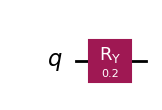

In [117]:
# One adjustable rotation angle
def one_qubit_circuit(theta):
    qc = QuantumCircuit(1)
    qc.ry(theta[0], 0)
    return qc

# Draw the circuit with a trial angle
one_qubit_circuit([0.2]).draw('mpl')


In [56]:
# The optimizer calls this function with different angles
def loss_one(theta):
    qc = one_qubit_circuit(theta)
    state = get_state(qc)
    loss = 1 - state_fidelity(target_one, state)
    history_one.append(loss)
    return loss


**The classical optimizer**

`minimize()` tries to make the returned loss smaller. We use **COBYLA**, which does not require us to implement a gradient.

- The second argument is the starting array of angles.
- `maxiter` limits the number of loss evaluations for COBYLA.
- `tol` controls the optimizer's stopping tolerance.
- `result.x` contains the optimized angles, and `result.nfev` is the number of loss evaluations.

Each call to the loss function appends a value to a history list. The horizontal axis of our training plots is therefore **loss evaluations**.


In [118]:
# Reset the history when rerunning the training
history_one = []

result_one = minimize(loss_one, [0.2], method='COBYLA', options={'maxiter': 100, 'tol': 1e-6})

trained_one = one_qubit_circuit(result_one.x)
state_one = get_state(trained_one)

print('Optimized angle:', np.round(result_one.x, 6))
print('Learned amplitudes:', np.round(state_one.data, 4))
print(f'Fidelity: {state_fidelity(target_one, state_one):.6f}')
print('Loss evaluations:', result_one.nfev)


Optimized angle: [1.982314]
Learned amplitudes: [0.5477+0.j 0.8367+0.j]
Fidelity: 1.000000
Loss evaluations: 32


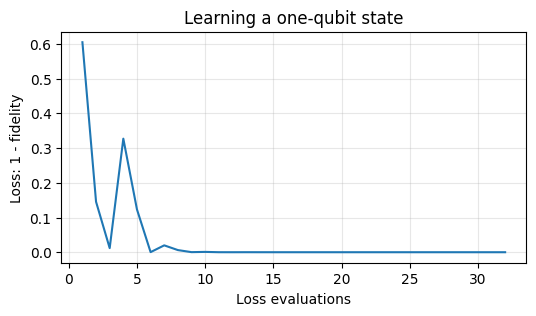

In [77]:
# Plot the training history
plt.figure(figsize=(6, 3))
plt.plot(np.arange(1, len(history_one) + 1), history_one)
plt.xlabel('Loss evaluations')
plt.ylabel('Loss: 1 - fidelity')
plt.title('Learning a one-qubit state')
plt.grid(alpha=0.3)
plt.show()


**Interpret the result**

- The expected amplitudes are approximately $[0.5477,\ 0.8367]$. Is the final fidelity close to one?
- Use the formula for $R_y$ above to check the angle against $2\arcsin(\sqrt{0.7})$.
- Does the loss decrease on every evaluation? The optimizer can try a worse angle while searching for a better one.

Equivalent solutions can differ by a global phase, so an overall minus sign in a statevector does not mean that training failed.


## Task 2: Train a circuit to prepare a Bell state

Now prepare

$$|\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}.$$

1. Start with two qubits in $|00\rangle$.
2. Apply an adjustable $R_y$ gate to qubit 0, followed by `cx(0, 1)`.
3. Train the angle using the same fidelity loss.
4. Compare the learned state with the Bell state and draw the trained circuit.

**Hint:** The circuit prepares $\cos(\theta/2)|00\rangle + \sin(\theta/2)|11\rangle$. The CNOT lets this circuit produce an entangled state.


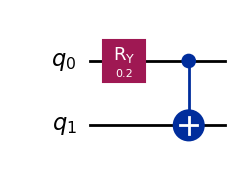

In [66]:
# Target Bell state
target_bell = np.array([1, 0, 0, 1], dtype=float) / np.sqrt(2)

def bell_circuit(theta):
    qc = QuantumCircuit(2)
    qc.ry(theta[0], 0)
    qc.cx(0, 1)
    return qc

bell_circuit([0.2]).draw('mpl')


In [67]:
# Same loss as before, now for a two-qubit state
def loss_bell(theta):
    qc = bell_circuit(theta)
    state = get_state(qc)
    loss = 1 - state_fidelity(target_bell, state)
    history_bell.append(loss)
    return loss

history_bell = []

result_bell = minimize(loss_bell, [0.2], method='COBYLA', options={'maxiter': 100, 'tol': 1e-6})

trained_bell = bell_circuit(result_bell.x)
state_bell = get_state(trained_bell)

print('Optimized angle:', np.round(result_bell.x, 6))
print('Learned amplitudes:', np.round(state_bell.data, 4))
print(f'Fidelity: {state_fidelity(target_bell, state_bell):.6f}')
print('Loss evaluations:', result_bell.nfev)


Optimized angle: [1.570797]
Learned amplitudes: [0.7071+0.j 0.    +0.j 0.    +0.j 0.7071+0.j]
Fidelity: 1.000000
Loss evaluations: 30


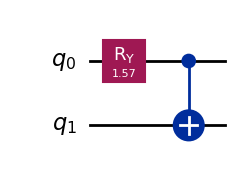

In [68]:
trained_bell.draw('mpl')

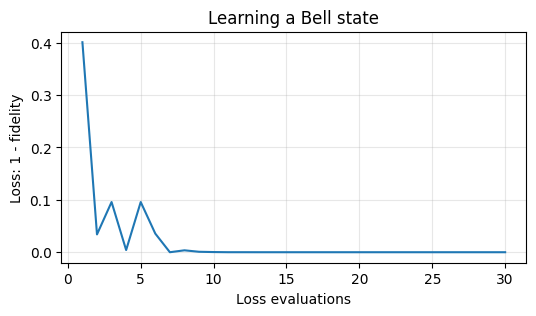

In [76]:
plt.figure(figsize=(6, 3))
plt.plot(np.arange(1, len(history_bell) + 1), history_bell)
plt.xlabel('Loss evaluations')
plt.ylabel('Loss: 1 - fidelity')
plt.title('Learning a Bell state')
plt.grid(alpha=0.3)
plt.show()


**Interpret the result**

The expected amplitudes are approximately $[0.7071,\ 0,\ 0,\ 0.7071]$, and one suitable angle is $\pi/2$.

What happens if you remove the CNOT and train again? Single-qubit rotations alone cannot create the Bell state's entanglement. For this target, a product state cannot have fidelity greater than $1/2$.


## Task 3: Variational amplitude encoding

We now want to encode a classical vector into a quantum state. For a nonzero real vector $\mathbf{x}$ containing $2^n$ entries, the target is

$$|x\rangle = \sum_{i=0}^{2^n-1}\frac{x_i}{\|\mathbf{x}\|}|i\rangle.$$

Three qubits have eight basis states, so we can use them to encode eight amplitudes. The normalization is essential: the squared magnitudes of a quantum state's amplitudes must sum to one.

1. Normalize the given vector and construct an exact reference circuit.
2. Construct a trainable circuit using $R_y$ rotations and CNOT gates.
3. Optimize its angles to approximate the target amplitudes.
4. Plot the target and learned amplitudes, and compare the circuit resources.
5. Measure the trained circuit using `qasm_simulator`.

This exercise fits **one circuit to one vector**. If the vector changes, train the circuit again. The input values are amplitudes after normalization and their squares are measurement probabilities.


In [29]:
# Eight real numbers encoded using three qubits
x = np.array([1, 2, 3, 4, 4, 3, 6, 1], dtype=float)
n = 3

target = x / np.linalg.norm(x)
labels = [format(i, f'0{n}b') for i in range(2**n)]

print('Input vector:', x)
print('Target amplitudes:', np.round(target, 4))
print('Sum of probabilities:', np.sum(np.abs(target)**2))


Input vector: [1. 2. 3. 4. 4. 3. 6. 1.]
Target amplitudes: [0.1043 0.2085 0.3128 0.417  0.417  0.3128 0.6255 0.1043]
Sum of probabilities: 1.0000000000000002


**Exact reference**

`StatePreparation(target)` constructs a gate that prepares the normalized target state from $|0\cdots0\rangle$. It provides a reference for comparison. We do not use this gate inside the trainable circuit.


Exact preparation fidelity: 1.000000


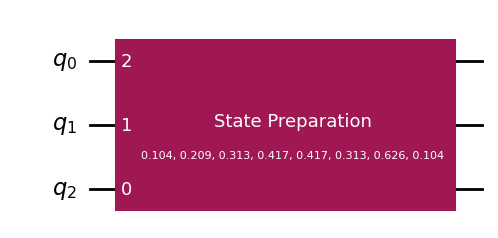

In [30]:
# Exact amplitude encoding
exact_circuit = QuantumCircuit(n)
exact_circuit.append(StatePreparation(target), list(reversed(range(n))))

exact_state = get_state(exact_circuit)
print(f'Exact preparation fidelity: {state_fidelity(target, exact_state):.6f}')

exact_circuit.draw('mpl')


**Our trainable circuit**

One layer contains an $R_y$ gate on each qubit, followed by a chain of CNOTs. After the repeated layers, we add one final set of $R_y$ gates.

For `n` qubits and `layers` repeated layers, there are `n * (layers + 1)` adjustable angles. With the defaults below, we train nine angles. The CNOT gates have no trainable angles.

We use real target amplitudes, for which $R_y$ rotations and CNOTs are a suitable starting point. Arbitrary complex target amplitudes would require a circuit that can also introduce relative complex phases.


In [119]:
# Build the trainable amplitude encoder
def amplitude_circuit(theta, n, layers):
    qc = QuantumCircuit(n)

    for layer in range(layers):
        # Adjustable rotations
        for qubit in range(n):
            qc.ry(theta[layer * n + qubit], qubit)

        # Entangle neighboring qubits
        for qubit in range(n - 1):
            qc.cx(qubit, qubit + 1)

        qc.barrier()

    # Final adjustable rotations
    for qubit in range(n):
        qc.ry(theta[layers * n + qubit], qubit)

    return qc


Number of trainable angles: 9


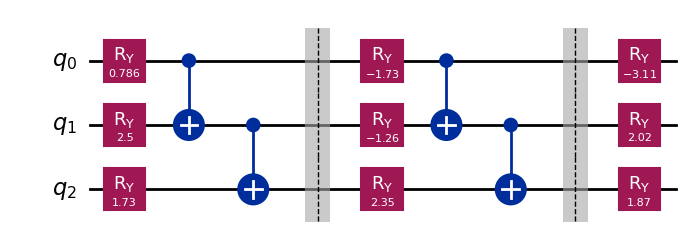

In [120]:
# Choose the circuit size and starting angles
layers = 2
num_parameters = n * (layers + 1)

# Fixed seed makes the starting angles reproducible
rng = np.random.default_rng(7)
initial_theta = rng.uniform(-np.pi, np.pi, num_parameters)

print('Number of trainable angles:', num_parameters)
amplitude_circuit(initial_theta, n, layers).draw('mpl')


In [121]:
# Fidelity loss for amplitude encoding
def loss_amplitude(theta):
    qc = amplitude_circuit(theta, n, layers)
    state = get_state(qc)
    loss = 1 - state_fidelity(target, state)
    history_amplitude.append(loss)
    return loss


In [122]:
# Train the amplitude encoder
history_amplitude = []

result_amplitude = minimize(loss_amplitude, initial_theta, method='COBYLA', options={'maxiter': 1000, 'tol': 1e-5})

trained_circuit = amplitude_circuit(result_amplitude.x, n, layers)
trained_state = get_state(trained_circuit)
final_fidelity = state_fidelity(target, trained_state)

print(f'Final fidelity: {final_fidelity:.8f}')
print('Loss evaluations:', result_amplitude.nfev)
print('Optimizer message:', result_amplitude.message)


Final fidelity: 0.99999470
Loss evaluations: 1000
Optimizer message: Maximum number of function evaluations has been exceeded.


**Compare the amplitudes**

An overall minus sign describes the same physical state and gives the same fidelity. Since this circuit has real amplitudes, we align that overall sign before making the comparison plot.

Optimization results can vary with the starting angles, optimizer version, and evaluation budget. If the evaluation limit is reached, inspect the final fidelity as the circuit may already be a useful approximation.


In [123]:
# Align a possible overall minus sign for the amplitude comparison
learned_amplitudes = trained_state.data.real.copy()
if np.dot(target, learned_amplitudes) < 0:
    learned_amplitudes = -learned_amplitudes

print('Target amplitudes: ', np.round(target, 4))
print('Learned amplitudes:', np.round(learned_amplitudes, 4))

Target amplitudes:  [0.1043 0.2085 0.3128 0.417  0.417  0.3128 0.6255 0.1043]
Learned amplitudes: [0.1028 0.2087 0.3137 0.4168 0.418  0.3121 0.625  0.105 ]


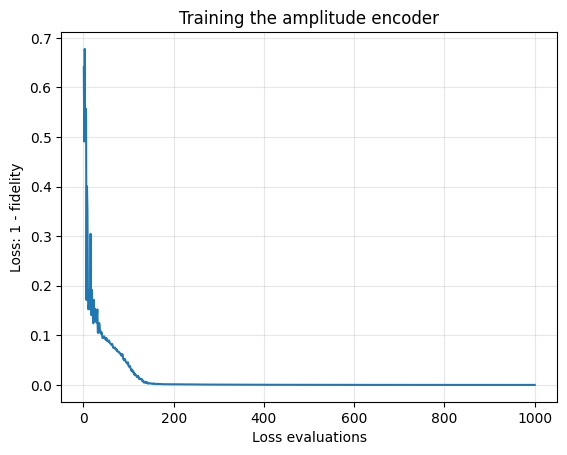

In [124]:
# Graph 1: Training loss
plt.plot(np.arange(1, len(history_amplitude) + 1), history_amplitude)
plt.xlabel('Loss evaluations')
plt.ylabel('Loss: 1 - fidelity')
plt.title('Training the amplitude encoder')
plt.grid(alpha=0.3)
plt.show()


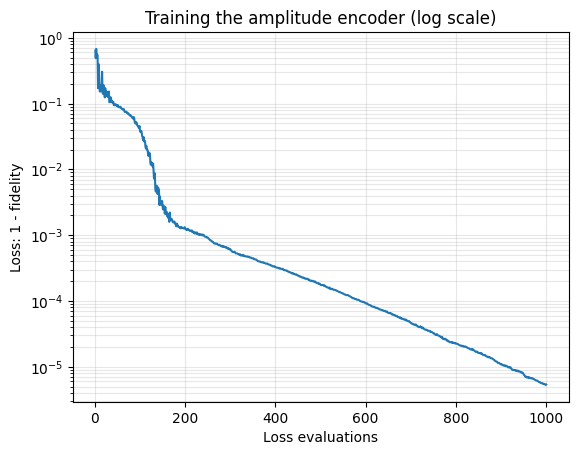

In [125]:
# Graph 2: Training loss on a log scale
plt.plot(np.arange(1, len(history_amplitude) + 1), history_amplitude)
plt.yscale('log')
plt.xlabel('Loss evaluations')
plt.ylabel('Loss: 1 - fidelity')
plt.title('Training the amplitude encoder (log scale)')
plt.grid(True, which='both', alpha=0.3)
plt.show()

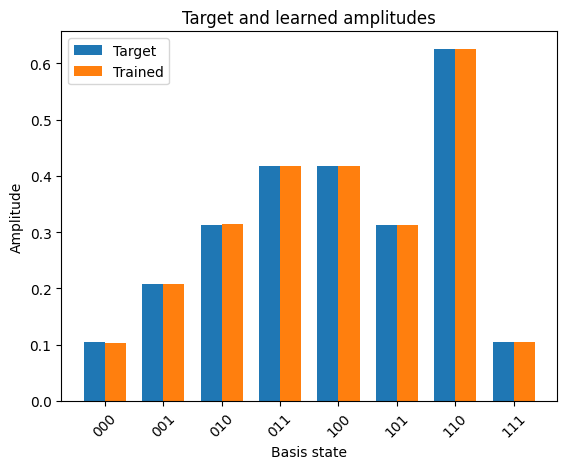

In [126]:
# Graph 2: Target and learned amplitudes
positions = np.arange(2**n)

plt.bar(positions - 0.18, target, width=0.36, label='Target')
plt.bar(positions + 0.18, learned_amplitudes, width=0.36, label='Trained')
plt.xticks(positions, labels, rotation=45)
plt.xlabel('Basis state')
plt.ylabel('Amplitude')
plt.title('Target and learned amplitudes')
plt.legend()
plt.show()

**Compare circuit resources**

A single `StatePreparation` box hides its underlying gates. To make a fair comparison, transpile both circuits to the same gate set with the same optimization level. Here, `u` is a general single-qubit gate and `cx` is the CNOT gate.

The variational circuit is not guaranteed to be shorter, especially for a small example. Compare the observed gate counts and fidelity, and remember that finding its angles also required classical optimization.


In [127]:
# Compile both circuits to the same gate set
exact_compiled = transpile( exact_circuit, basis_gates=['u', 'cx'], optimization_level=1)
trained_compiled = transpile( trained_circuit, basis_gates=['u', 'cx'], optimization_level=1)

for name, qc in [('Exact', exact_compiled), ('Variational', trained_compiled)]:
    print(name)
    print('  Circuit depth:', qc.depth())
    print('  Total gates:', qc.size())
    print('  CNOT gates:', qc.count_ops().get('cx', 0))

Exact
  Circuit depth: 9
  Total gates: 11
  CNOT gates: 4
Variational
  Circuit depth: 7
  Total gates: 13
  CNOT gates: 4


**Measure the trained state**

We trained with full statevectors. Now measure the learned circuit, as in the earlier exercises. The histogram shows probabilities proportional to the **squared amplitudes**. With finitely many shots, the counts fluctuate around their ideal values.


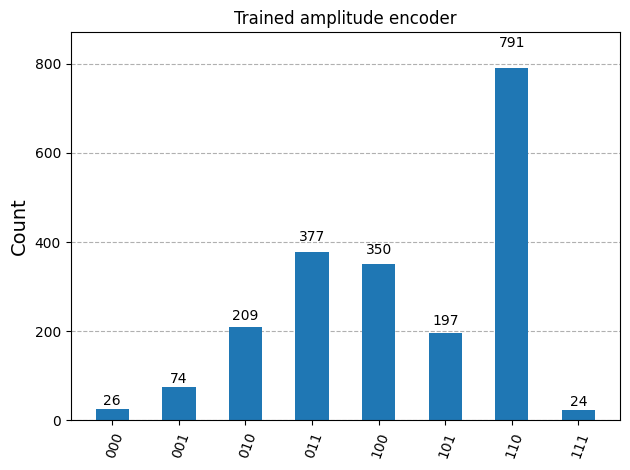

In [128]:
# Add measurements to a copy of the trained circuit
measured_circuit = trained_circuit.measure_all(inplace=False)

backend = Aer.get_backend('qasm_simulator')
compiled = transpile(measured_circuit, backend)
job = backend.run(compiled, shots=2048)
counts = job.result().get_counts()

counts = {bitstring[::-1]: count for bitstring, count in counts.items()}

plot_histogram(counts, title='Trained amplitude encoder')

**Interpret the result**

1. How close are the learned amplitudes to the target amplitudes?
2. Which basis states have the highest measurement probability? Compare with `target**2`.
3. Does your trained circuit use fewer CNOTs than the exact reference?
4. Why does a histogram alone not reveal the signs of the amplitudes?


## References

- [IBM Quantum: Statevector](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.quantum_info.Statevector)
- [IBM Quantum: StatePreparation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.StatePreparation)
- [SciPy: minimize with COBYLA](https://docs.scipy.org/doc/scipy/reference/optimize.minimize-cobyla.html)
- [IBM Quantum: Variational algorithms](https://quantum.cloud.ibm.com/learning/en/courses/variational-algorithm-design/variational-algorithms)
